Beyond Hearing MADAV Project

Code by Júlia Escoriza and Sara Gibert

The code structure follows the Index Structure of this project's report

# **1. INTRODUCTION**

## **RUN TO START**

In [ ]:
# Install packages if missing
if(!requireNamespace("ggplot2", quietly=TRUE)) install.packages("ggplot2")
if(!requireNamespace("factoextra", quietly=TRUE)) install.packages("factoextra")
if(!requireNamespace("dplyr", quietly=TRUE)) install.packages("dplyr")
if(!requireNamespace("GGally", quietly=TRUE)) install.packages("GGally")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘xts’, ‘TTR’, ‘quadprog’, ‘quantmod’, ‘colorspace’, ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘tseries’, ‘urca’, ‘zoo’, ‘RcppArmadillo’, ‘Deriv’, ‘forecast’, ‘microbenchmark’, ‘rbibutils’, ‘doBy’, ‘SparseM’, ‘MatrixModels’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘Rdpack’, ‘RcppEigen’, ‘lazyeval’, ‘carData’, ‘Formula’, ‘pbkrtest’, ‘quantreg’, ‘lme4’, ‘crosstalk’, ‘estimability’, ‘mvtnorm’, ‘numDeriv’, ‘corrplot’, ‘viridis’, ‘car’, ‘DT’, ‘ellipse’, ‘emmeans’, ‘flashClust’, ‘leaps’, ‘multcompView’, ‘scatterplot3d’, ‘ggsci’, ‘cowplot’, ‘ggsignif’, ‘gridExtra’, ‘polynom’, ‘rstatix’, ‘plyr’, ‘abind’, ‘dendextend’, ‘FactoMineR’, ‘ggpubr’, ‘reshape2’, ‘ggrepel’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘patchwork’, ‘ggstats’




In [ ]:
# Install libraries
library(ggplot2)
library(dplyr)
library(haven)
library(dplyr)
library(scales)
library(tidyverse)
library(GGally)



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ lubridate 1.9.4     ✔ tibble    3.3.0
✔ purrr     1.2.0     ✔ tidyr     1.3.1
✔ readr     2.1.6     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ readr::col_factor() masks scales::col_factor()
✖ purrr::discard()    masks scales::discard()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [ ]:
#Load Data
hearing_data  <- read_xpt("data/AUQ_J.xpt") #hearing data
demo_data <- read_xpt("data/DEMO_J.xpt") #demographic data
depression_data <- read_xpt("data/DPQ_J.xpt") #depression data
smoking_data <- read_xpt("data/SMQ_J.xpt") #smoking data

In [ ]:
theme_report <- function() {
  theme_bw() +
  theme(
    # Add light, dashed gridlines
    panel.grid.major = element_line(color = "gray92", linetype = "dashed"),
    panel.grid.minor = element_blank(), # Keep minor gridlines off for a cleaner look

    # Border and Title styling
    panel.border = element_rect(colour = "black", fill = NA, linewidth = 0.7),
    plot.title = element_text(face = "bold", hjust = 0.5, size = 13, margin = margin(b = 10)),

    # Axis and Tick styling
    axis.title = element_text(size = 11, color = "black"),
    axis.text = element_text(color = "black", size = 10),
    axis.ticks = element_line(colour = "black"),
    axis.ticks.length = unit(0.15, "cm")
  )
}

## **Clean data**

In [ ]:
nhanes_missing_codes <- c(7, 9, 77, 99, 777, 999)

# 7 -> Refuse
# 9 -> Don't know
# 77 -> Refuse
# 99 -> Don't know
# 777/999 -> Refused / Unknown

In [ ]:
clean_nhanes_missing <- function(df) {
  df %>%
    mutate(across(
      where(is.numeric),
      ~ replace(., . %in% nhanes_missing_codes, NA)
    ))
}

Clean each dataset separately

In [ ]:
demo_data <- demo_data %>%
  clean_nhanes_missing()

In [ ]:
names(demo_data)

[1] "SEQN"     "SDDSRVYR" "RIDSTATR" "RIAGENDR" "RIDAGEYR" "RIDAGEMN"
 [7] "RIDRETH1" "RIDRETH3" "RIDEXMON" "RIDEXAGM" "DMQMILIZ" "DMQADFC" 
[13] "DMDBORN4" "DMDCITZN" "DMDYRSUS" "DMDEDUC3" "DMDEDUC2" "DMDMARTL"
[19] "RIDEXPRG" "SIALANG"  "SIAPROXY" "SIAINTRP" "FIALANG"  "FIAPROXY"
[25] "FIAINTRP" "MIALANG"  "MIAPROXY" "MIAINTRP" "AIALANGA" "DMDHHSIZ"
[31] "DMDFMSIZ" "DMDHHSZA" "DMDHHSZB" "DMDHHSZE" "DMDHRGND" "DMDHRAGZ"
[37] "DMDHREDZ" "DMDHRMAZ" "DMDHSEDZ" "WTINT2YR" "WTMEC2YR" "SDMVPSU" 
[43] "SDMVSTRA" "INDHHIN2" "INDFMIN2" "INDFMPIR"

In [ ]:
depression_data <- depression_data %>%
  clean_nhanes_missing()

In [ ]:
hearing_data <- hearing_data %>%
  clean_nhanes_missing()

In [ ]:
smoking_data <- smoking_data %>%
  clean_nhanes_missing()

Merge datasets after cleaning

In [ ]:
df <- demo_data %>%
  left_join(depression_data, by = "SEQN") %>%
  left_join(hearing_data, by = "SEQN") %>%
  left_join(smoking_data, by = "SEQN")


In [ ]:
names(df)

[1] "SEQN"     "SDDSRVYR" "RIDSTATR" "RIAGENDR" "RIDAGEYR" "RIDAGEMN"
  [7] "RIDRETH1" "RIDRETH3" "RIDEXMON" "RIDEXAGM" "DMQMILIZ" "DMQADFC" 
 [13] "DMDBORN4" "DMDCITZN" "DMDYRSUS" "DMDEDUC3" "DMDEDUC2" "DMDMARTL"
 [19] "RIDEXPRG" "SIALANG"  "SIAPROXY" "SIAINTRP" "FIALANG"  "FIAPROXY"
 [25] "FIAINTRP" "MIALANG"  "MIAPROXY" "MIAINTRP" "AIALANGA" "DMDHHSIZ"
 [31] "DMDFMSIZ" "DMDHHSZA" "DMDHHSZB" "DMDHHSZE" "DMDHRGND" "DMDHRAGZ"
 [37] "DMDHREDZ" "DMDHRMAZ" "DMDHSEDZ" "WTINT2YR" "WTMEC2YR" "SDMVPSU" 
 [43] "SDMVSTRA" "INDHHIN2" "INDFMIN2" "INDFMPIR" "DPQ010"   "DPQ020"  
 [49] "DPQ030"   "DPQ040"   "DPQ050"   "DPQ060"   "DPQ070"   "DPQ080"  
 [55] "DPQ090"   "DPQ100"   "AUQ054"   "AUQ060"   "AUQ070"   "AUQ080"  
 [61] "AUQ090"   "AUQ400"   "AUQ410A"  "AUQ410B"  "AUQ410C"  "AUQ410D" 
 [67] "AUQ410E"  "AUQ410F"  "AUQ410G"  "AUQ410H"  "AUQ410I"  "AUQ410J" 
 [73] "AUQ156"   "AUQ420"   "AUQ430"   "AUQ139"   "AUQ144"   "AUQ147"  
 [79] "AUQ149A"  "AUQ149B"  "AUQ149C"  "AUQ153"   "AUQ630"   "AUQ440"  
 [85] "AUQ450A"  "AUQ450B"  "AUQ450C"  "AUQ450D"  "AUQ450E"  "AUQ450F" 
 [91] "AUQ460"   "AUQ470"   "AUQ101"   "AUQ110"   "AUQ480"   "AUQ490"  
 [97] "AUQ191"   "AUQ250"   "AUQ255"   "AUQ260"   "AUQ270"   "AUQ280"  
[103] "AUQ500"   "AUQ300"   "AUQ310"   "AUQ320"   "AUQ330"   "AUQ340"  
[109] "AUQ350"   "AUQ360"   "AUQ370"   "AUQ510"   "AUQ380"   "SMQ020"  
[115] "SMD030"   "SMQ040"   "SMQ050Q"  "SMQ050U"  "SMD057"   "SMQ078"  
[121] "SMD641"   "SMD650"   "SMD093"   "SMDUPCA"  "SMD100BR" "SMD100FL"
[127] "SMD100MN" "SMD100LN" "SMD100TR" "SMD100NI" "SMD100CO" "SMQ621"  
[133] "SMD630"   "SMQ661"   "SMQ665A"  "SMQ665B"  "SMQ665C"  "SMQ665D" 
[139] "SMQ670"   "SMQ848"   "SMQ852Q"  "SMQ852U"  "SMQ890"   "SMQ895"  
[145] "SMQ900"   "SMQ905"   "SMQ910"   "SMQ915"   "SMAQUEX2"

Create age groups after merging

In [ ]:
df <- df %>%
  mutate(
    age_group = cut(
      RIDAGEYR,
      breaks = c(17, 39, 59, 79, 120),
      labels = c("18–39", "40–59", "60–79", "80+")
    )
  )


Drop invalid cases

In [ ]:
df_clean <- df %>%
  filter(
    !is.na(RIDAGEYR),
    !is.na(RIAGENDR),
    !is.na(age_group)
    # add hearing and depression variables here
  )


In [ ]:
names(df_clean)

[1] "SEQN"      "SDDSRVYR"  "RIDSTATR"  "RIAGENDR"  "RIDAGEYR"  "RIDAGEMN" 
  [7] "RIDRETH1"  "RIDRETH3"  "RIDEXMON"  "RIDEXAGM"  "DMQMILIZ"  "DMQADFC"  
 [13] "DMDBORN4"  "DMDCITZN"  "DMDYRSUS"  "DMDEDUC3"  "DMDEDUC2"  "DMDMARTL" 
 [19] "RIDEXPRG"  "SIALANG"   "SIAPROXY"  "SIAINTRP"  "FIALANG"   "FIAPROXY" 
 [25] "FIAINTRP"  "MIALANG"   "MIAPROXY"  "MIAINTRP"  "AIALANGA"  "DMDHHSIZ" 
 [31] "DMDFMSIZ"  "DMDHHSZA"  "DMDHHSZB"  "DMDHHSZE"  "DMDHRGND"  "DMDHRAGZ" 
 [37] "DMDHREDZ"  "DMDHRMAZ"  "DMDHSEDZ"  "WTINT2YR"  "WTMEC2YR"  "SDMVPSU"  
 [43] "SDMVSTRA"  "INDHHIN2"  "INDFMIN2"  "INDFMPIR"  "DPQ010"    "DPQ020"   
 [49] "DPQ030"    "DPQ040"    "DPQ050"    "DPQ060"    "DPQ070"    "DPQ080"   
 [55] "DPQ090"    "DPQ100"    "AUQ054"    "AUQ060"    "AUQ070"    "AUQ080"   
 [61] "AUQ090"    "AUQ400"    "AUQ410A"   "AUQ410B"   "AUQ410C"   "AUQ410D"  
 [67] "AUQ410E"   "AUQ410F"   "AUQ410G"   "AUQ410H"   "AUQ410I"   "AUQ410J"  
 [73] "AUQ156"    "AUQ420"    "AUQ430"    "AUQ139"    "AUQ144"    "AUQ147"   
 [79] "AUQ149A"   "AUQ149B"   "AUQ149C"   "AUQ153"    "AUQ630"    "AUQ440"   
 [85] "AUQ450A"   "AUQ450B"   "AUQ450C"   "AUQ450D"   "AUQ450E"   "AUQ450F"  
 [91] "AUQ460"    "AUQ470"    "AUQ101"    "AUQ110"    "AUQ480"    "AUQ490"   
 [97] "AUQ191"    "AUQ250"    "AUQ255"    "AUQ260"    "AUQ270"    "AUQ280"   
[103] "AUQ500"    "AUQ300"    "AUQ310"    "AUQ320"    "AUQ330"    "AUQ340"   
[109] "AUQ350"    "AUQ360"    "AUQ370"    "AUQ510"    "AUQ380"    "SMQ020"   
[115] "SMD030"    "SMQ040"    "SMQ050Q"   "SMQ050U"   "SMD057"    "SMQ078"   
[121] "SMD641"    "SMD650"    "SMD093"    "SMDUPCA"   "SMD100BR"  "SMD100FL" 
[127] "SMD100MN"  "SMD100LN"  "SMD100TR"  "SMD100NI"  "SMD100CO"  "SMQ621"   
[133] "SMD630"    "SMQ661"    "SMQ665A"   "SMQ665B"   "SMQ665C"   "SMQ665D"  
[139] "SMQ670"    "SMQ848"    "SMQ852Q"   "SMQ852U"   "SMQ890"    "SMQ895"   
[145] "SMQ900"    "SMQ905"    "SMQ910"    "SMQ915"    "SMAQUEX2"  "age_group"

## VARIABLE CONSTRUCTION

### DEPRESSION VARIABLES

In [ ]:
phq_vars <- c(
  "DPQ010", "DPQ020", "DPQ030", "DPQ040", "DPQ050",
  "DPQ060", "DPQ070", "DPQ080", "DPQ090"
)

In [ ]:
depression_data <- depression_data %>%
  rowwise() %>%
  mutate(
    phq9_total = sum(c_across(all_of(phq_vars)), na.rm = FALSE)
  ) %>%
  ungroup()

In [ ]:
depression_data <- depression_data %>%
  mutate(
    depressed = case_when(
      phq9_total >= 10 ~ 1,
      phq9_total < 10  ~ 0,
      TRUE ~ NA_real_
    )
  )

In [ ]:
summary(depression_data$phq9_total)
table(depression_data$depressed)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.    NA's 
  0.000   0.000   2.000   3.241   5.000  25.000     465 


   0    1 
4609  459 

### HEARING DATA

In [ ]:
hearing_data <- hearing_data %>%
  mutate(
    hearing_level = factor(
      AUQ054,
      levels = c(1, 2, 3, 4, 5, 6),
      labels = c(
        "Excellent",
        "Good",
        "A little trouble",
        "Moderate trouble",
        "A lot of trouble",
        "Deaf"
      ),
      ordered = TRUE
    )
  )

In [ ]:
hearing_data <- hearing_data %>%
  mutate(
    hearing_loss = case_when(
      AUQ054 <= 2 ~ 0,  # Excellent / Good
      AUQ054 >= 3 ~ 1,
      TRUE ~ NA_real_
    )
  )

In [ ]:
table(hearing_data$hearing_level)
table(hearing_data$hearing_loss)


       Excellent             Good A little trouble Moderate trouble 
            4361             3074              899              372 
A lot of trouble             Deaf 
             166               22 


   0    1 
7435 1459 

Megre Variables

In [ ]:
df <- demo_data %>%
  inner_join(depression_data, by = "SEQN") %>%
  inner_join(hearing_data, by = "SEQN") %>%
  inner_join(smoking_data, by = "SEQN")

In [ ]:
df_final <- df %>%
  filter(
    !is.na(depressed),
    !is.na(hearing_level),
    !is.na(RIDAGEYR),
    !is.na(RIAGENDR)
  )

Different of age

In [ ]:
df_final <- df_final %>%
  mutate(
    age_group = cut(
      RIDAGEYR,
      breaks = c(17, 39, 59, 79, 120),
      labels = c("18–39", "40–59", "60–79", "80+")
    )
  )

In [ ]:
dim(df_final)
table(df_final$age_group)
table(df_final$hearing_level, df_final$depressed)

[1] 5020  154


18–39 40–59 60–79   80+ 
 1704  1540  1471   305 

                  
                      0    1
  Excellent        1785   88
  Good             1807  172
  A little trouble  602  115
  Moderate trouble  262   53
  A lot of trouble  102   21
  Deaf               10    3

# **2. DATA SOURCES AND VARIABLES**

## 2.1 MODEL 1: DEMOGRAPHIC

### Age by Sex Distribution

In [ ]:
# Sex into integers
demo_data <- demo_data %>%  # Take the existing data frame 'demo_data' and start a dplyr pipeline (%>%) to modify it.
  mutate(                   # Use mutate() from dplyr to create or transform variables in the data frame.
    sex = factor(RIAGENDR, levels = c(1, 2), labels = c("Male", "Female"))
  )

# Create a new variable called 'sex' and turn it into a factor (categorical variable).
# The source variable is 'RIAGENDR', which contains numeric codes for gender.
# Define the numeric values that correspond to each category (1 = Male, 2 = Female).
# Assign human-readable labels to the factor levels: 1 becomes "Male", 2 becomes "Female".

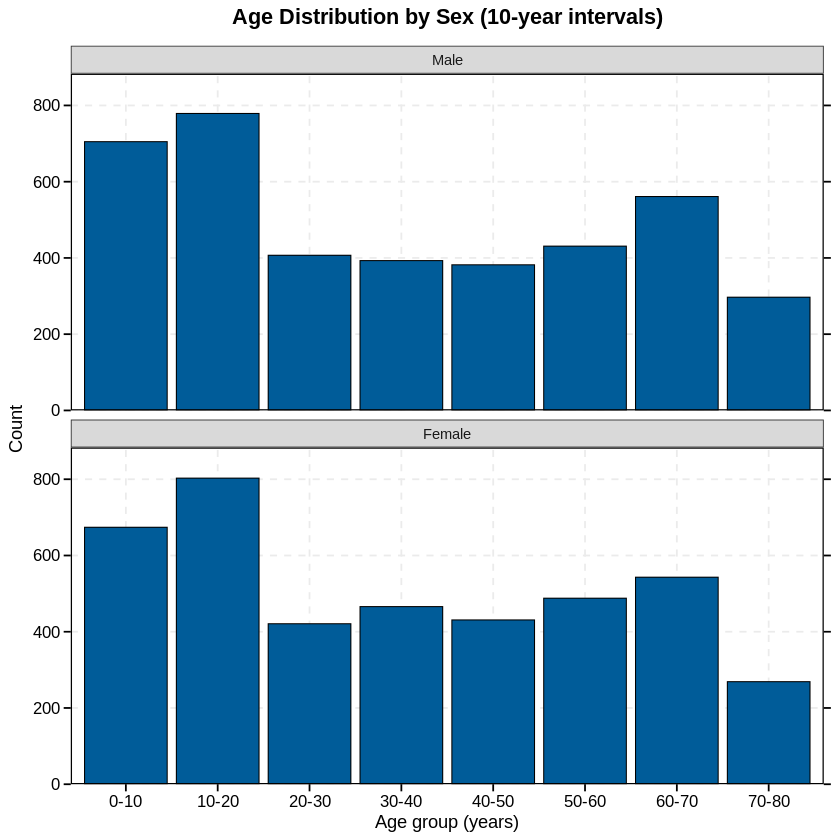

In [ ]:
# 2. Transformed Plot
demo_data %>%
  filter(!is.na(RIDAGEYR), RIDAGEYR > 0) %>%
  mutate(age_group = cut(
    RIDAGEYR,
    breaks = seq(0, 80, by = 10),
    right = FALSE,
    labels = paste(seq(0, 70, by = 10), seq(10, 80, by = 10), sep = "-")
  ))  %>%
  filter(!is.na(age_group)) %>%
  ggplot(aes(x = age_group)) +
  # Using the professional blue with black outlines
  geom_bar(fill = "#005C99", color = "black", linewidth = 0.3) +

  # Stacked facets (ncol = 1) as requested
  facet_wrap(~ sex, ncol = 1) +

  # Adding the "Lattice style" tick marks on all sides
  scale_y_continuous(
    expand = expansion(mult = c(0, 0.1)),
    sec.axis = dup_axis(labels = NULL, name = NULL)
  ) +

  labs(
    title = "Age Distribution by Sex (10-year intervals)",
    x = "Age group (years)",
    y = "Count"
  ) +
  theme_report()

### Race / Ethnicity Distribution

In [ ]:
demo_data <- demo_data %>%     # Start with the existing data frame 'demo_data' and begin a dplyr pipeline.
  mutate(                      # Use mutate() to create or modify variables within the dataset.
    origin = factor(           # Create a new variable named 'origin' and convert it to a factor (categorical variable).
      RIDRETH3,                # Source variable 'RIDRETH3' holds numeric codes for race/ethnicity categories.
      levels = c(1, 2, 3, 4, 5, 6),
      labels = c(
        "Mexican American",
        "Other Hispanic",
        "Non-Hispanic White",
        "Non-Hispanic Black",
        "Non-Hispanic Asian",
        "Other / Multi-Racial"
      )
    )
  ) %>%
  filter(!is.na(origin))   # remove NAs safely

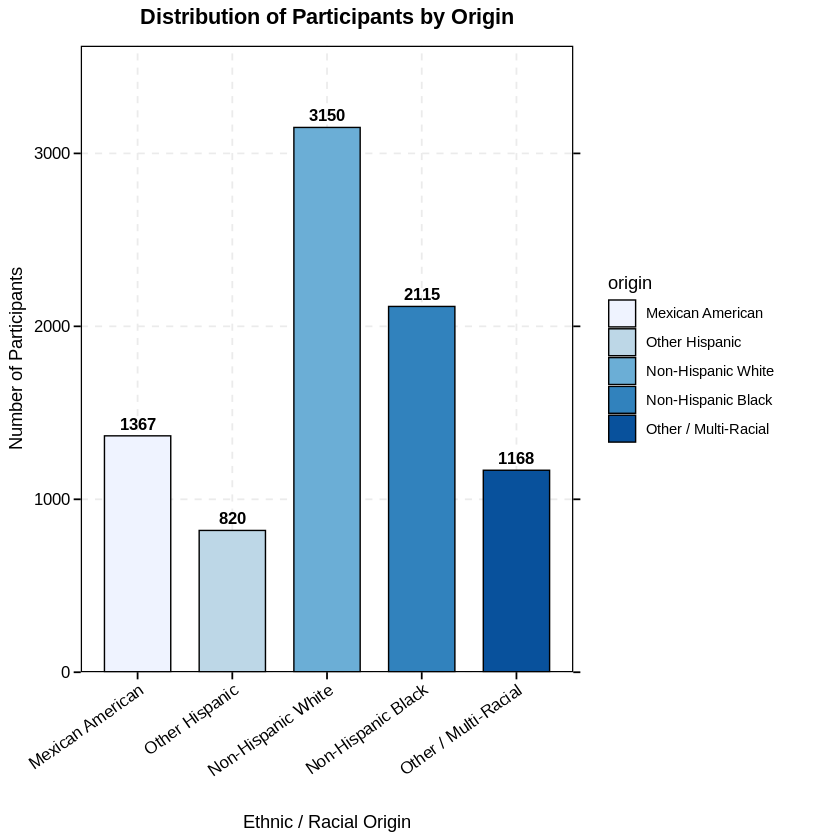

In [ ]:
ggplot(demo_data, aes(x = origin, fill = origin)) +
  geom_bar(color = "black", linewidth = 0.4, width = 0.7) +
  geom_text(
    stat = "count",
    aes(label = after_stat(count)),
    vjust = -0.5,
    size = 3.5,
    fontface = "bold"
  ) +
  scale_fill_brewer(palette = "Blues") +
  scale_y_continuous(
    expand = expansion(mult = c(0, 0.15)),
    sec.axis = dup_axis(labels = NULL, name = NULL)
  ) +
  labs(
    title = "Distribution of Participants by Origin",
    x = "Ethnic / Racial Origin",
    y = "Number of Participants"
  ) +
  theme_report() +
  theme(axis.text.x = element_text(angle = 35, hjust = 1))

## 2.2 MODEL 2: SOCIOECONOMIC CONTROLS

### Level of Studies Distribution

In [ ]:
# Inspect education variable
table(demo_data$DMDEDUC2, useNA = "ifany")  # Create a frequency table of the variable 'DMDEDUC2'.

# Recode DMDEDUC2 into readable labels
demo_data <- demo_data %>%                  # Start a dplyr pipeline with the dataset 'demo_data'.
  mutate(Education = case_when(             # Use mutate() to create or modify variables in the dataset.
    DMDEDUC2 == 1 ~ "Less than 9th grade",
    DMDEDUC2 == 2 ~ "9-11th grade",
    DMDEDUC2 == 3 ~ "High school/GED",
    DMDEDUC2 == 4 ~ "Some college/AA",
    DMDEDUC2 == 5 ~ "College grad+",
    TRUE ~ NA_character_                    # All other values (including missing ones) become NA (missing character).
  ))

# Summarize data: count and percentage
edu_dist <- demo_data %>%                    # Start another pipeline using the updated dataset.
  filter(!is.na(Education)) %>%              # Exclude rows with missing 'Education' values for accurate summaries.
  count(Education) %>%                       # Count the number of participants in each education category.
  mutate(percent = n / sum(n))               # Compute the proportion (percentage) each category represents.



   1    2    3    4    5 <NA> 
 468  612 1258 1664 1282 3336 

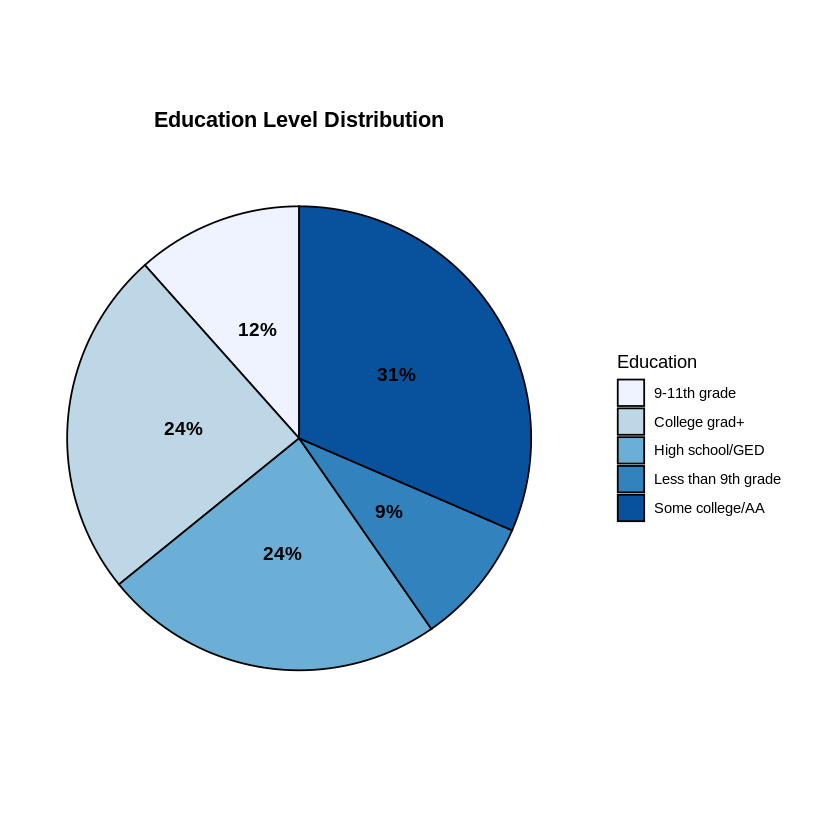

In [ ]:
ggplot(edu_dist, aes(x = "", y = percent, fill = Education)) +
  geom_col(color = "black", linewidth = 0.5) +
  coord_polar(theta = "y") +
  geom_text(aes(label = paste0(round(percent*100), "%")),
            position = position_stack(vjust = 0.5),
            size = 4,
            fontface = "bold") +
  # Using the Blues palette to match the scientific report style
  scale_fill_brewer(palette = "Blues") +
  labs(title = "Education Level Distribution") +
  theme_report() +
  # Cleaning up the grid and axes specifically for the pie chart view
  theme(
    axis.title = element_blank(),
    axis.text = element_blank(),
    axis.ticks = element_blank(),
    panel.grid.major = element_blank(),
    panel.border = element_blank(), # Circular charts look better without the box
    legend.position = "right"
  )

### Income Distribution

In [ ]:
demo_data <- demo_data %>%                    # Start a dplyr pipeline with your dataset 'demo_data'.
  mutate(Income8 = case_when(                 # Use mutate() to create or modify variables in the dataset.
    INDHHIN2 %in% c(1,2) ~ "<$10,000",
    INDHHIN2 %in% c(3,4) ~ "$10,000–$19,999",
    INDHHIN2 == 5 ~ "$20,000–$24,999",
    INDHHIN2 == 6 ~ "$25,000–$34,999",
    INDHHIN2 == 7 ~ "$35,000–$44,999",
    INDHHIN2 == 8 ~ "$45,000–$54,999",
    INDHHIN2 %in% c(9,10) ~ "$55,000–$74,999",
    INDHHIN2 %in% c(11,12) ~ "$75,000+",
    TRUE ~ NA_character_                      # All other or missing values become NA (missing character).
  ))

# Define the logical order of income categories
income_levels8 <- c("<$10,000", "$10,000–$19,999", "$20,000–$24,999",
                    "$25,000–$34,999", "$35,000–$44,999", "$45,000–$54,999",
                    "$55,000–$74,999", "$75,000+")

# Convert 'Income8' into an ordered factor
demo_data$Income8 <- factor(demo_data$Income8, levels = income_levels8)

# Summarize counts and percentages for each income group
income_dist8 <- demo_data %>% # Start a pipeline using the cleaned dataset.
  filter(!is.na(Income8)) %>% # Remove rows where 'Income8' is missing (no valid income info).
  count(Income8) %>%          # Count how many participants fall into each income category.
  mutate(percent = n / sum(n))# Add a new column showing each category’s share of the total (proportion).

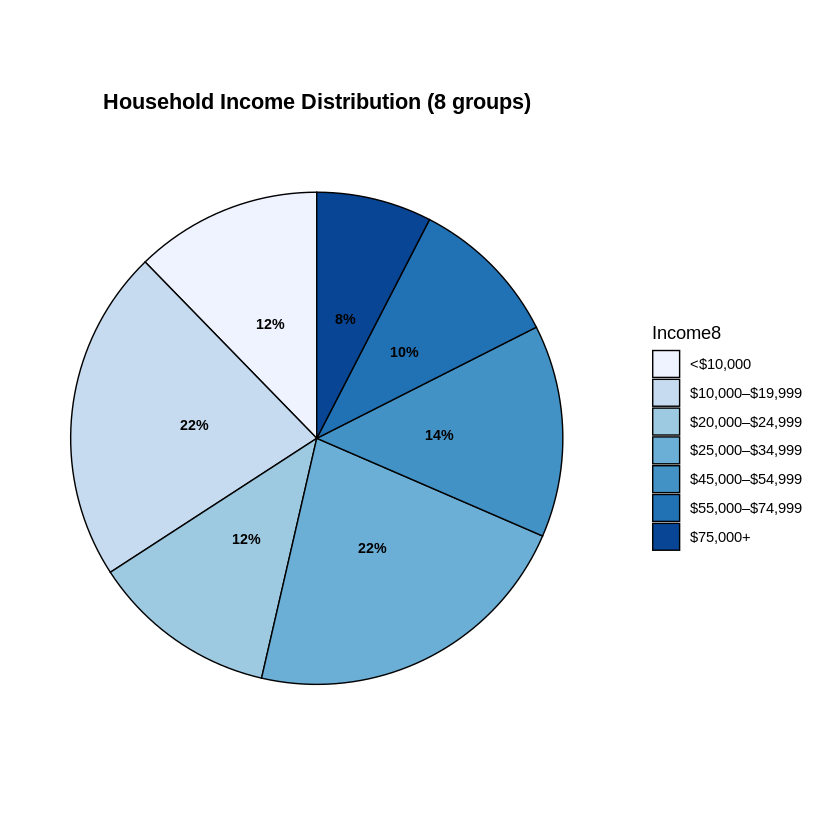

In [ ]:
ggplot(income_dist8, aes(x = "", y = percent, fill = Income8)) +
  geom_col(color = "black", linewidth = 0.4) +
  coord_polar(theta = "y") +
  geom_text(aes(label = paste0(round(percent*100), "%")),
            position = position_stack(vjust = 0.5),
            size = 3,
            fontface = "bold") +
  # Using the Blues palette (supports up to 9 levels) for professional consistency
  scale_fill_brewer(palette = "Blues") +
  labs(title = "Household Income Distribution (8 groups)") +
  theme_report() +
  # Adjusting the theme specifically for the circular format
  theme(
    axis.title = element_blank(),
    axis.text = element_blank(),
    axis.ticks = element_blank(),
    panel.grid.major = element_blank(),
    panel.border = element_blank(),
    legend.position = "right",
    aspect.ratio = 1 # Overriding to keep the pie chart circular
  )

## 2.3 MODEL 3: SMOKING HABITS / DRUG USE

### Current Smoking Status Among Adults

In [ ]:
clean_smoking <- smoking_data %>%     # Start a dplyr pipeline using the dataset 'smoking_data'.
  filter(SMQ040 %in% c(1, 2, 3)) %>%  # Step 1: Keep only rows where SMQ040 has valid codes (1, 2, or 3).
                                      # This removes any missing or invalid responses.

  mutate(                             # Step 2: Transform the variable for readability.
    SMQ040 = factor(SMQ040,           # Convert SMQ040 into a factor (categorical variable).
                    levels = c(1, 2, 3),  # Specify the numeric codes to map.
                    labels = c("Every day", "Some days", "Not at all")) # Assign human-readable labels for each category:
  )

In [ ]:
total_n <- nrow(clean_smoking)  # Step 1: Count the total number of rows in 'clean_smoking'.
                                # This gives the denominator for calculating percentages.

summary_smoke <- clean_smoking %>%  # Start a dplyr pipeline using the cleaned smoking dataset.
  group_by(SMQ040) %>%              # Step 2: Group the data by smoking frequency (Every day, Some days, Not at all).
  summarise(n = n()) %>%            # Step 3: Count the number of participants in each smoking category.
  mutate(percent = 100 * n / total_n) # Step 4: Calculate the percentage of participants in each category.

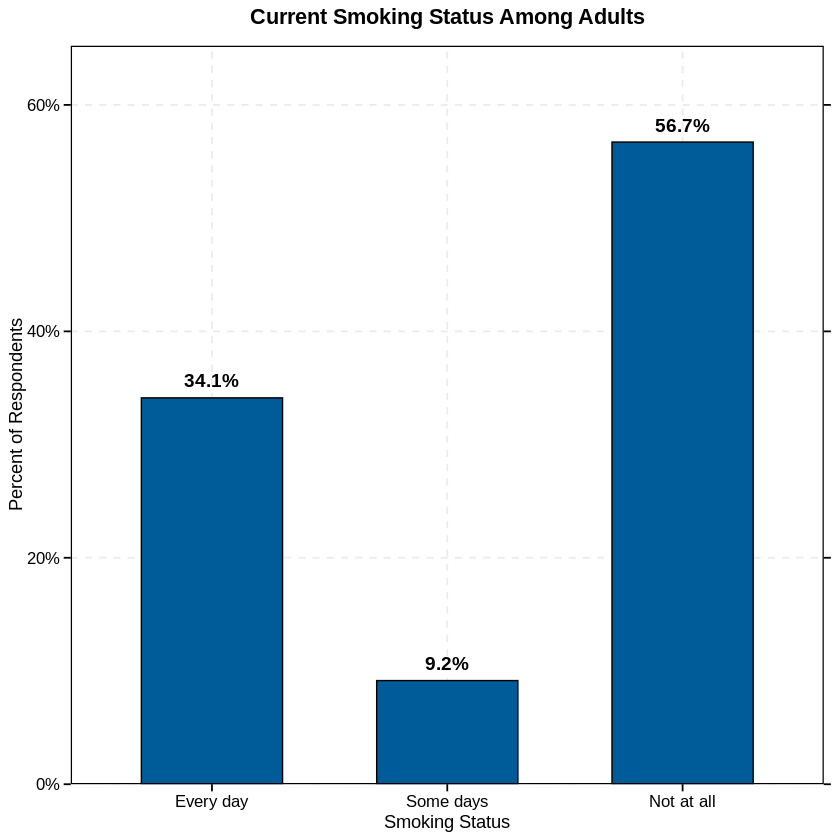

In [ ]:
ggplot(summary_smoke, aes(x = SMQ040, y = percent)) +
  # Using the professional blue with a clean black outline
  geom_col(fill = "#005C99", color = "black", width = 0.6, linewidth = 0.4) +

  # Percentage labels
  geom_text(aes(label = paste0(round(percent, 1), "%")),
            vjust = -0.8, color = "black", size = 4, fontface = "bold") +

  # Boxed style with secondary axis ticks
  scale_y_continuous(
    labels = function(x) paste0(x, "%"),
    expand = expansion(mult = c(0, 0.15)),
    sec.axis = dup_axis(labels = NULL, name = NULL)
  ) +

  labs(
    title = "Current Smoking Status Among Adults",
    x = "Smoking Status",
    y = "Percent of Respondents"
  ) +
  theme_report()

### Age at which Respondents Started Smoking Regularly

In [ ]:
df <- read_xpt("data/SMQ_J.xpt") # Step 1: Read an XPT (SAS Transport) file into R.

In [ ]:
# Clean based on when people started smoking
df2 <- df %>%                               # Start a dplyr pipeline using the raw dataset 'df' (from SMQ_J.xpt).
  mutate(age_start = SMD030) %>%            # Step 1: Create a new variable 'age_start' from 'SMD030',
  filter(age_start >= 7 & age_start <= 76)  # Step 2: Keep only rows where 'age_start' is within a plausible range (7–76 years).

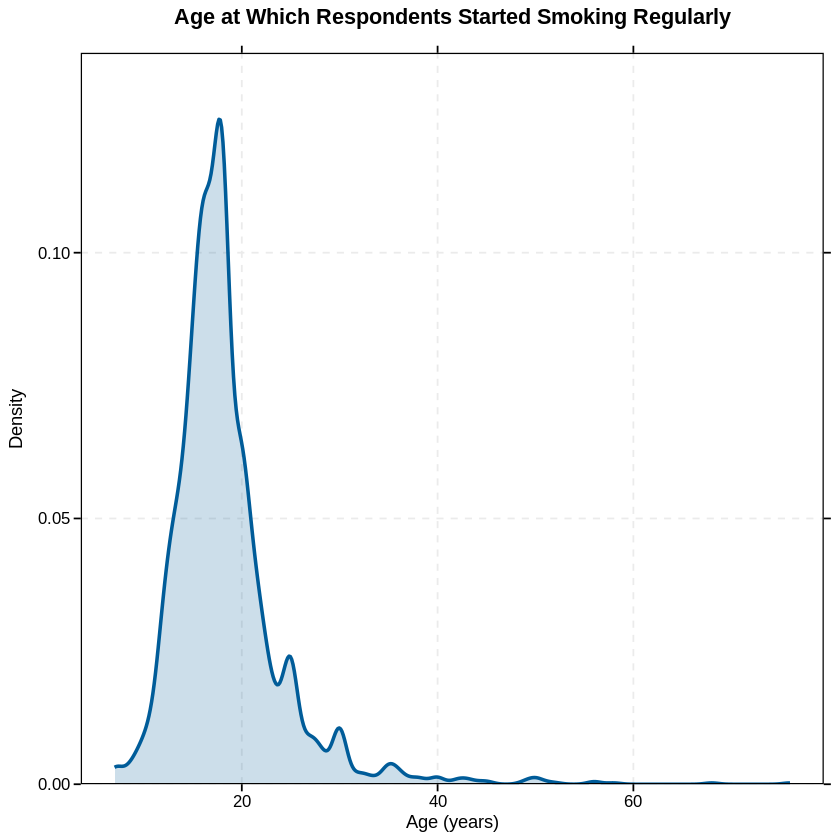

In [ ]:
ggplot(df2, aes(x = age_start)) +
  # Using the professional blue with a light fill to match the reference shading
  geom_density(fill = "#005C99", alpha = 0.2, color = "#005C99", linewidth = 1) +

  # Adding boxed tick marks on all sides
  scale_y_continuous(
    expand = expansion(mult = c(0, 0.1)),
    sec.axis = dup_axis(labels = NULL, name = NULL)
  ) +
  scale_x_continuous(
    sec.axis = dup_axis(labels = NULL, name = NULL)
  ) +

  labs(
    title = "Age at Which Respondents Started Smoking Regularly",
    x = "Age (years)",
    y = "Density"
  ) +
  theme_report()

## 2.4 FURTHER ANALYSIS

In [ ]:
df_final %>%
  group_by(hearing_level) %>%
  summarise(
    depression_rate = mean(depressed, na.rm = TRUE),
    n = n()
  )

hearing_level,depression_rate,n
<ord>,<dbl>,<int>
Excellent,0.04698345,1873
Good,0.08691258,1979
A little trouble,0.16039052,717
Moderate trouble,0.16825397,315
A lot of trouble,0.17073171,123
Deaf,0.23076923,13


### VISUALIZATION: Hearing VS Depression

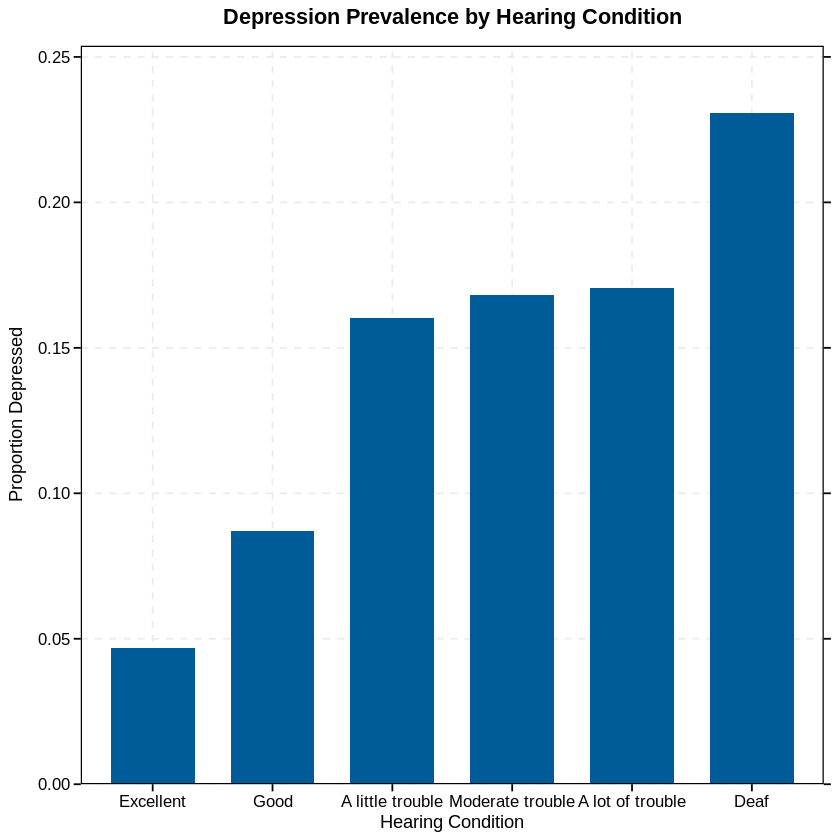

In [ ]:
ggplot(df_final, aes(x = hearing_level, y = depressed)) +
  # Using a blue that matches the reference (#005C99 is a professional scientific blue)
  stat_summary(fun = mean, geom = "bar", fill = "#005C99", width = 0.7) +

  # Add secondary axes to create the "boxed" tick marks on top and right
  scale_y_continuous(
    expand = expansion(mult = c(0, 0.1)), # Ensures bars start exactly at the x-axis
    sec.axis = dup_axis(labels = NULL, name = NULL)
  ) +

  # For discrete X axis, we use the theme border for the top line
  labs(
    title = "Depression Prevalence by Hearing Condition",
    x = "Hearing Condition",
    y = "Proportion Depressed"
  ) +
  theme_report()

### VISUALIZATION: Depression by hearing, differentiation by age

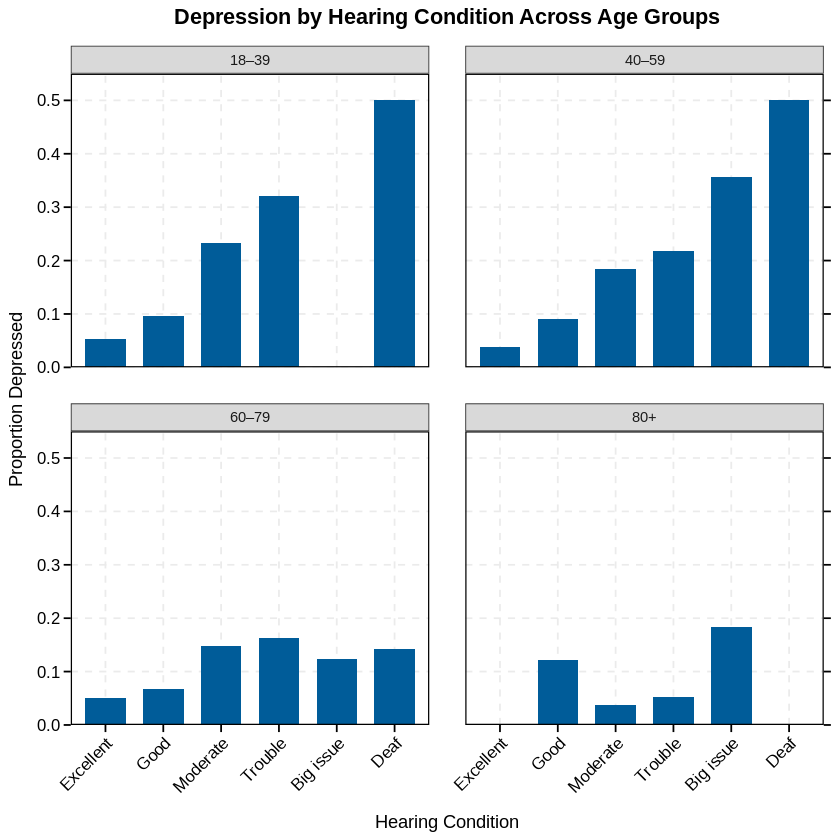

In [ ]:
# If using ggsave to export for your report:
# ggsave("depression_plot.png", width = 12, height = 7, dpi = 300)

ggplot(df_final, aes(x = hearing_level, y = depressed)) +
  stat_summary(fun = mean, geom = "bar", fill = "#005C99", width = 0.7) +
  facet_wrap(~ age_group) +
  scale_x_discrete(labels = c(
    "A little trouble" = "Moderate",
    "Moderate trouble" = "Trouble",
    "A lot of trouble" = "Big issue",
    "severe" = "Severe Loss"
  )) +
  scale_y_continuous(
    expand = expansion(mult = c(0, 0.1)),
    sec.axis = dup_axis(labels = NULL, name = NULL)
  ) +
  labs(
    title = "Depression by Hearing Condition Across Age Groups",
    x = "Hearing Condition",
    y = "Proportion Depressed"
  ) +
  theme_report() +
  # This part handles the overlap specifically:
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1, vjust = 1), # Tilts labels
    panel.spacing = unit(1.5, "lines") # Adds space between the facet boxes
  )

### VISUALIZATION: Difficulty Concentrating

In [ ]:
df_final <- df_final %>%
  mutate(
    concentration_problem = case_when(
      DPQ080 >= 2 ~ 1,
      DPQ080 < 2 ~ 0,
      TRUE ~ NA_real_
    )
  )

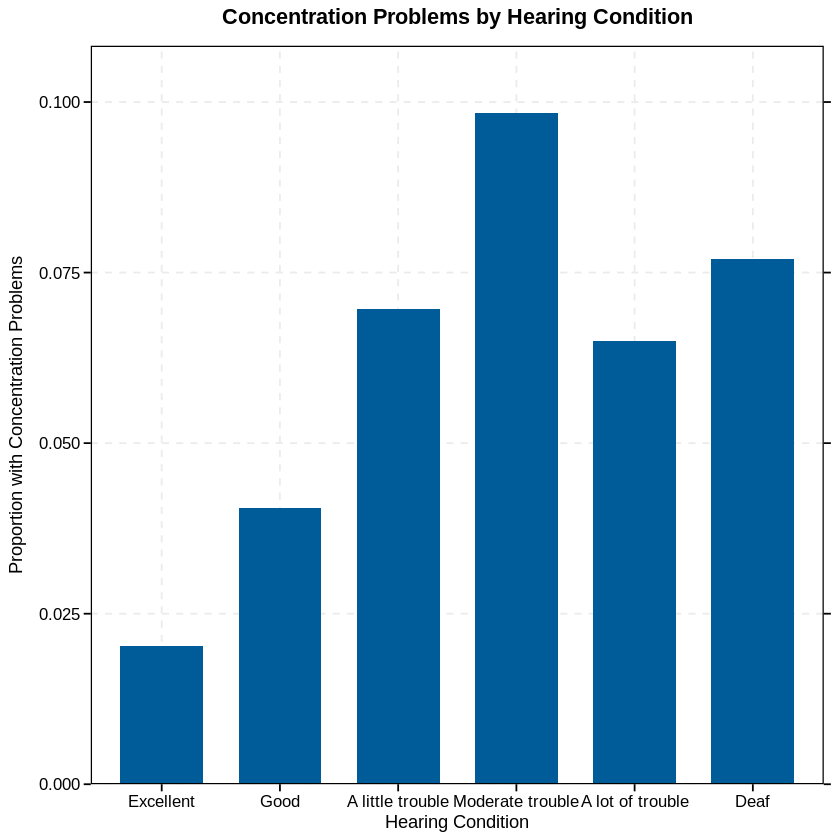

In [ ]:
ggplot(df_final, aes(x = hearing_level, y = concentration_problem)) +
  # Using the reference blue (#005C99) for report consistency
  stat_summary(fun = mean, geom = "bar", fill = "#005C99", width = 0.7) +

  # Adding secondary axes for the 'boxed' tick mark look
  scale_y_continuous(
    expand = expansion(mult = c(0, 0.1)),
    sec.axis = dup_axis(labels = NULL, name = NULL)
  ) +

  labs(
    title = "Concentration Problems by Hearing Condition",
    x = "Hearing Condition",
    y = "Proportion with Concentration Problems"
  ) +
  theme_report()

### VISUALIZATION: Hearing Loss and Trouble Concentrating

Merge Depression - Hearing data


In [ ]:
merged_data <- merge(hearing_data, depression_data, by = "SEQN")

Remove NAs

In [ ]:
clean_data <- merged_data %>%
  filter(!is.na(DPQ070), !is.na(AUQ054)) %>%  # remove missing values
  mutate(
    DPQ070 = factor(DPQ070,
                    levels = c(0, 1, 2, 3),
                    labels = c("Not at all", "Several days", "More than half the days", "Nearly every day")),
    AUQ054 = factor(AUQ054,
                    levels = c(1, 2, 3, 4, 5, 6),
                    labels = c("Excellent", "Good", "A little trouble", "Moderate trouble", "A lot of trouble", "Deaf"))
  ) %>%
  droplevels()  # remove unused factor levels (especially NA)

In [ ]:
summary_data <- clean_data %>%
  group_by(AUQ054) %>%
  summarise(
    n = n(),
    trouble_count = sum(DPQ070 != "Not at all", na.rm = TRUE),
    trouble_rate = 100 * trouble_count / n
  ) %>%
  filter(!is.na(AUQ054))  # remove any leftover NA rows just in case

Visualization

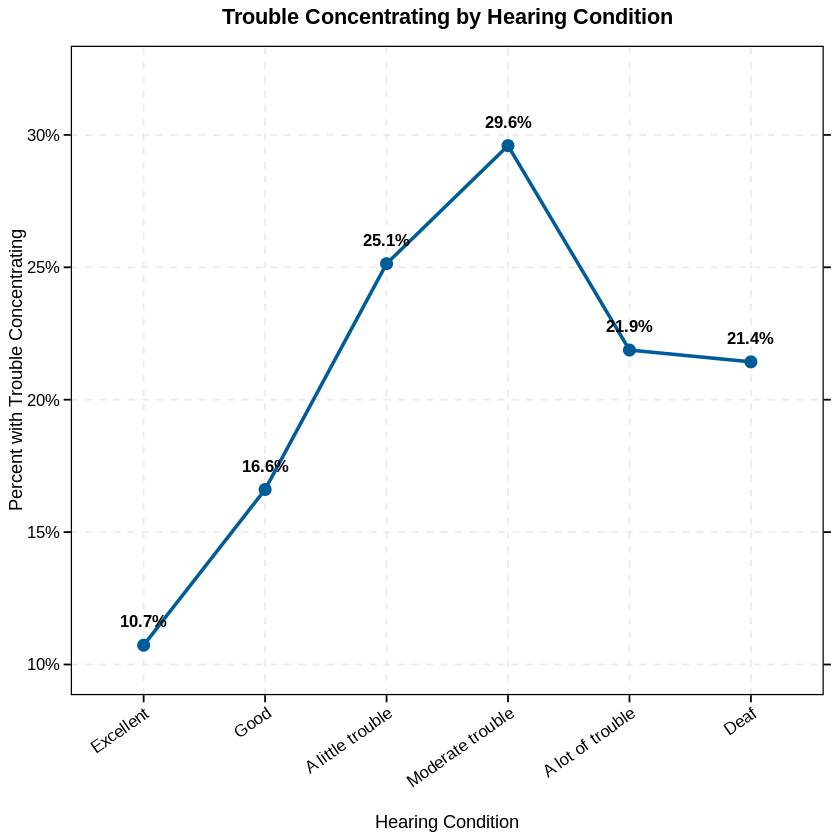

In [ ]:
ggplot(summary_data, aes(x = AUQ054, y = trouble_rate, group = 1)) +
  # Using the professional blue for the line
  geom_line(color = "#005C99", linewidth = 1) +

  # Solid blue points to match the scientific style
  geom_point(color = "#005C99", size = 3) +

  # Percentage labels
  geom_text(aes(label = paste0(round(trouble_rate, 1), "%")),
            vjust = -1.5, color = "black", size = 3.5, fontface = "bold") +

  # Boxed style with secondary axis ticks and percentage formatting
  scale_y_continuous(
    labels = function(x) paste0(x, "%"),
    expand = expansion(mult = c(0.1, 0.2)), # Extra room at the top for labels
    sec.axis = dup_axis(labels = NULL, name = NULL)
  ) +

  labs(
    title = "Trouble Concentrating by Hearing Condition",
    x = "Hearing Condition",
    y = "Percent with Trouble Concentrating"
  ) +
  theme_report() +
  # Angle the labels slightly to handle potential overlap on the x-axis
  theme(axis.text.x = element_text(angle = 35, hjust = 1))

# **3. METHODOLOGY**

In [ ]:
install.packages("effects")
library(effects)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘mitools’, ‘survey’, ‘insight’


Loading required package: carData

lattice theme set by effectsTheme()
See ?effectsTheme for details.



In [ ]:
#Load Data Again, since data cleaning is also being made form scratch in here
hearing_data  <- read_xpt("data/AUQ_J.xpt")
demo_data <- read_xpt("data/DEMO_J.xpt")
depression_data <- read_xpt("data/DPQ_J.xpt")
smoking_data <- read_xpt("data/SMQ_J.xpt")

## 3.1 Hearing Condition and Depression

In [ ]:
#Join Data
nhanes <- demo_data %>%
  left_join(hearing_data, by = "SEQN") %>%
  left_join(depression_data, by = "SEQN") %>%
  left_join(demo_data, by = "SEQN") %>%
  left_join(smoking_data, by = "SEQN")

In [ ]:
#Ommit NA
data <- nhanes %>%
  select(AUQ054, DPQ020) %>%
  na.omit()


In [ ]:
#See columns in our data
names(data)

[1] "AUQ054" "DPQ020"

In [ ]:
#Make Correlation Test
cor.test(data$AUQ054,
         data$DPQ020,
         method = "spearman")


Warning message in cor.test.default(data$AUQ054, data$DPQ020, method = "spearman"):
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  data$AUQ054 and data$DPQ020
S = 1.8973e+10, p-value < 2.2e-16
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.1382596 


In [ ]:
#Make Linear Regression
model <- lm(DPQ020 ~ AUQ054, data = data)
summary(model)



Call:
lm(formula = DPQ020 ~ AUQ054, data = data)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.4485 -0.3579 -0.3261 -0.3261  8.6739 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) 0.294191   0.013663  21.531  < 2e-16 ***
AUQ054      0.031862   0.004166   7.648 2.43e-14 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.7626 on 5091 degrees of freedom
Multiple R-squared:  0.01136,	Adjusted R-squared:  0.01116 
F-statistic: 58.49 on 1 and 5091 DF,  p-value: 2.425e-14


`geom_smooth()` using formula = 'y ~ x'


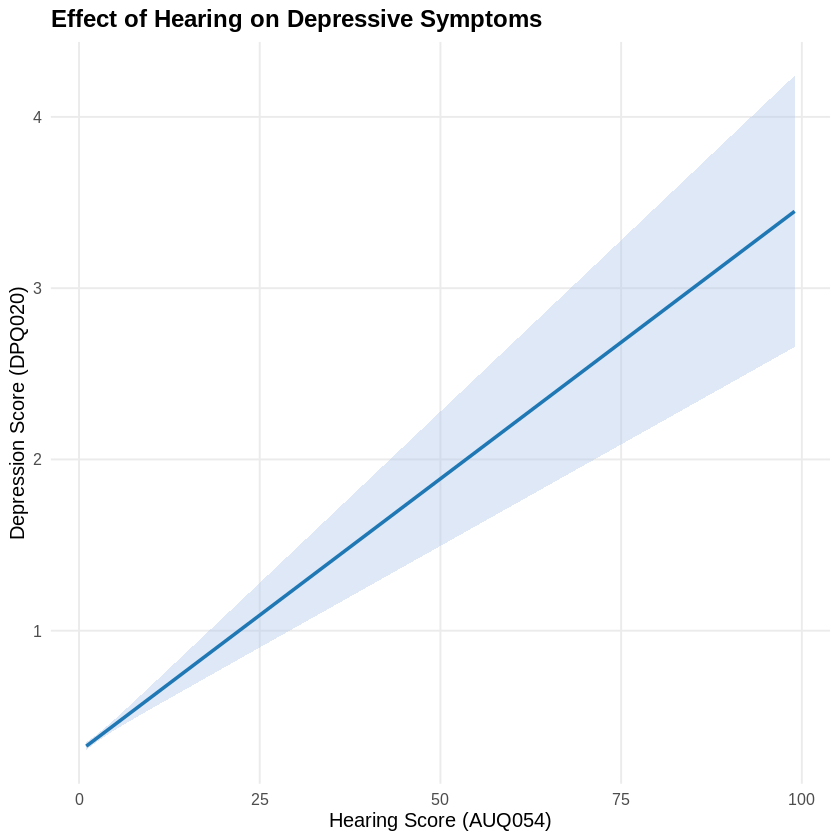

In [ ]:
ggplot(model, aes(x = AUQ054, y = DPQ020)) +
  geom_smooth(
    method = "lm",
    se = TRUE,
    color = "#1f77b4",      # blue line (same tone as effect plots)
    fill = "#aec7e8",       # light blue CI
    linewidth = 1
  ) +
  labs(
    title = "Effect of Hearing on Depressive Symptoms",
    x = "Hearing Score (AUQ054)",
    y = "Depression Score (DPQ020)"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    panel.grid.minor = element_blank(),
    plot.title = element_text(face = "bold")
  )


## 3.2 MODEL 1: Multiple Regression based on Age

In [ ]:
data_model <- hearing_data %>%
  select(SEQN, AUQ054) %>%
  inner_join(depression_data %>% select(SEQN, DPQ020), by = "SEQN") %>%
  inner_join(demo_data %>% select(SEQN, RIDAGEYR, RIAGENDR), by = "SEQN")

In [ ]:
data_model <- data_model %>%
  filter(
    AUQ054 %in% c(1, 2),
    !is.na(DPQ020),
    !is.na(RIDAGEYR),
    !is.na(RIAGENDR)
  )

In [ ]:
data_model$RIAGENDR <- factor(data_model$RIAGENDR,
                              levels = c(1, 2),
                              labels = c("Male", "Female"))

In [ ]:
model_multi <- lm(DPQ020 ~ AUQ054 + RIDAGEYR + RIAGENDR, data = data_model)

In [ ]:
#Compare it with simple regression
model_simple <- lm(DPQ020 ~ AUQ054, data = data_model)

summary(model_simple)
summary(model_multi)



Call:
lm(formula = DPQ020 ~ AUQ054, data = data_model)

Residuals:
    Min      1Q  Median      3Q     Max 
-0.3496 -0.3496 -0.2456 -0.2456  8.7544 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  0.14165    0.03483   4.066 4.87e-05 ***
AUQ054       0.10398    0.02182   4.764 1.96e-06 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.6805 on 3891 degrees of freedom
Multiple R-squared:  0.0058,	Adjusted R-squared:  0.005545 
F-statistic:  22.7 on 1 and 3891 DF,  p-value: 1.963e-06



Call:
lm(formula = DPQ020 ~ AUQ054 + RIDAGEYR + RIAGENDR, data = data_model)

Residuals:
    Min      1Q  Median      3Q     Max 
-0.4496 -0.3206 -0.2729 -0.1585  8.7297 

Coefficients:
                 Estimate Std. Error t value Pr(>|t|)    
(Intercept)     0.1208056  0.0439287   2.750  0.00599 ** 
AUQ054          0.1171071  0.0220125   5.320 1.10e-07 ***
RIDAGEYR       -0.0013243  0.0006205  -2.134  0.03288 *  
RIAGENDRFemale  0.1184394  0.0217813   5.438 5.73e-08 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.6777 on 3889 degrees of freedom
Multiple R-squared:  0.01438,	Adjusted R-squared:  0.01362 
F-statistic: 18.91 on 3 and 3889 DF,  p-value: 3.567e-12


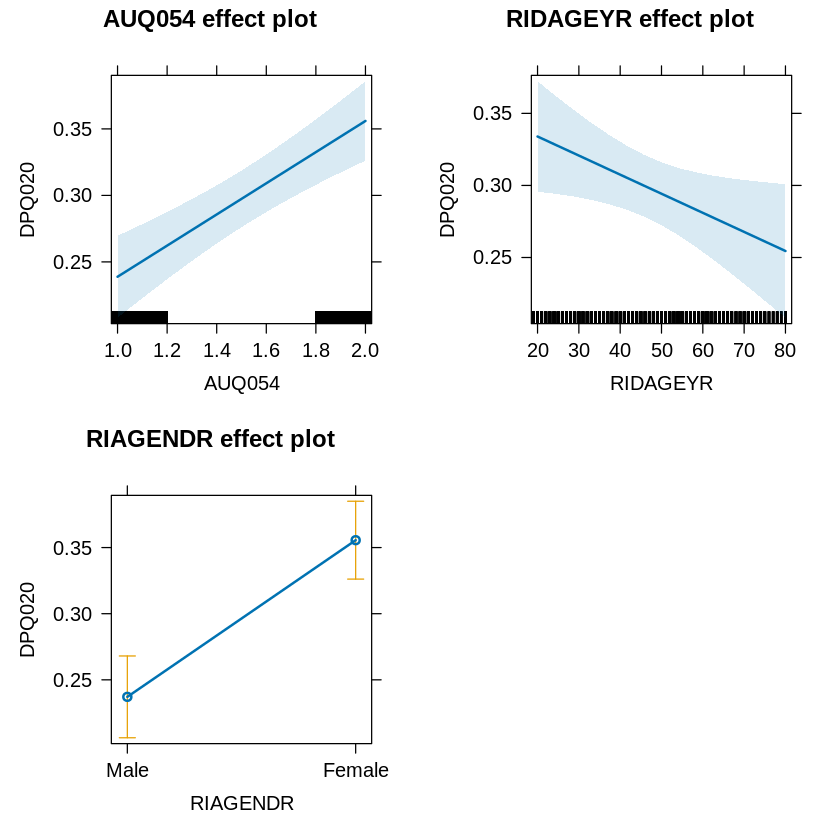

In [ ]:
plot(allEffects(model_multi))

## 3.3 MODEL 2: Multiple Regression based on Household Income

In [ ]:
# Keep only valid income codes
valid_income <- c(1:15)  # excluding 77, 99, missing
demo_data <- demo_data %>%
  filter(INDHHIN2 %in% valid_income)

# Optionally, create broader categories for easier interpretation
demo_data <- demo_data %>%
  mutate(income_cat = case_when(
    INDHHIN2 %in% 1:5  ~ "Under $25k",
    INDHHIN2 %in% 6:10 ~ "$25k-$74k",
    INDHHIN2 %in% c(12,14) ~ "$75k-$99k",
    INDHHIN2 == 15      ~ "$100k and Over"
  ))

In [ ]:
data_model2 <- hearing_data %>%
  select(SEQN, AUQ054) %>%
  inner_join(depression_data %>% select(SEQN, DPQ020), by = "SEQN") %>%
  inner_join(demo_data %>% select(SEQN, INDHHIN2), by = "SEQN")

In [ ]:
names(data_model2)

[1] "SEQN"     "AUQ054"   "DPQ020"   "INDHHIN2"

In [ ]:
data_model <- data_model %>%
  filter(
    AUQ054 %in% c(1, 2),
    !is.na(DPQ020),
  )

In [ ]:
model_income <- lm(DPQ020 ~ AUQ054 + INDHHIN2, data = data_model2)
summary(model_income)


Call:
lm(formula = DPQ020 ~ AUQ054 + INDHHIN2, data = data_model2)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.1706 -0.3984 -0.2771 -0.1791  8.8209 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept)  0.502899   0.027056  18.588  < 2e-16 ***
AUQ054       0.027657   0.004848   5.705 1.23e-08 ***
INDHHIN2    -0.023428   0.002476  -9.461  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.7441 on 4633 degrees of freedom
  (368 observations deleted due to missingness)
Multiple R-squared:  0.02716,	Adjusted R-squared:  0.02674 
F-statistic: 64.66 on 2 and 4633 DF,  p-value: < 2.2e-16


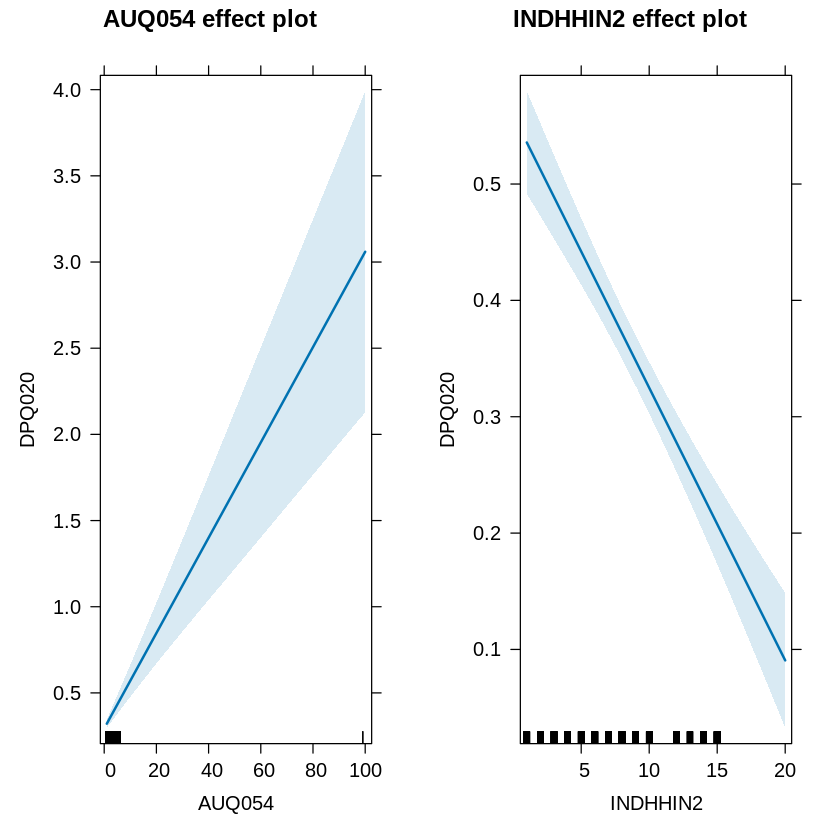

In [ ]:
plot(allEffects(model_income))

## 3.4 MODEL 3: Multiple Regression based on Smoking Habits

In [ ]:
data_model3 <- hearing_data %>%
  select(SEQN, AUQ054) %>%
  inner_join(depression_data %>% select(SEQN, DPQ020), by = "SEQN") %>%
  inner_join(smoking_data %>% select(SEQN, SMD030), by = "SEQN")

In [ ]:
data_model3 <- data_model3 %>%
  filter(
    AUQ054 %in% c(1, 2),
    !is.na(DPQ020),
    !is.na(SMD030),
  )


In [ ]:
names(data_model3)

[1] "SEQN"   "AUQ054" "DPQ020" "SMD030"

In [ ]:
model_multi <- lm(DPQ020 ~ AUQ054 + SMD030, data = data_model3)
summary(model_multi)


Call:
lm(formula = DPQ020 ~ AUQ054 + SMD030, data = data_model3)

Residuals:
    Min      1Q  Median      3Q     Max 
-0.4250 -0.4189 -0.3128  0.5785  8.5794 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)   
(Intercept)  0.2113986  0.0665526   3.176  0.00152 **
AUQ054       0.1068075  0.0401798   2.658  0.00794 **
SMD030      -0.0003389  0.0004415  -0.768  0.44281   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.7566 on 1441 degrees of freedom
Multiple R-squared:  0.005265,	Adjusted R-squared:  0.003885 
F-statistic: 3.814 on 2 and 1441 DF,  p-value: 0.02229


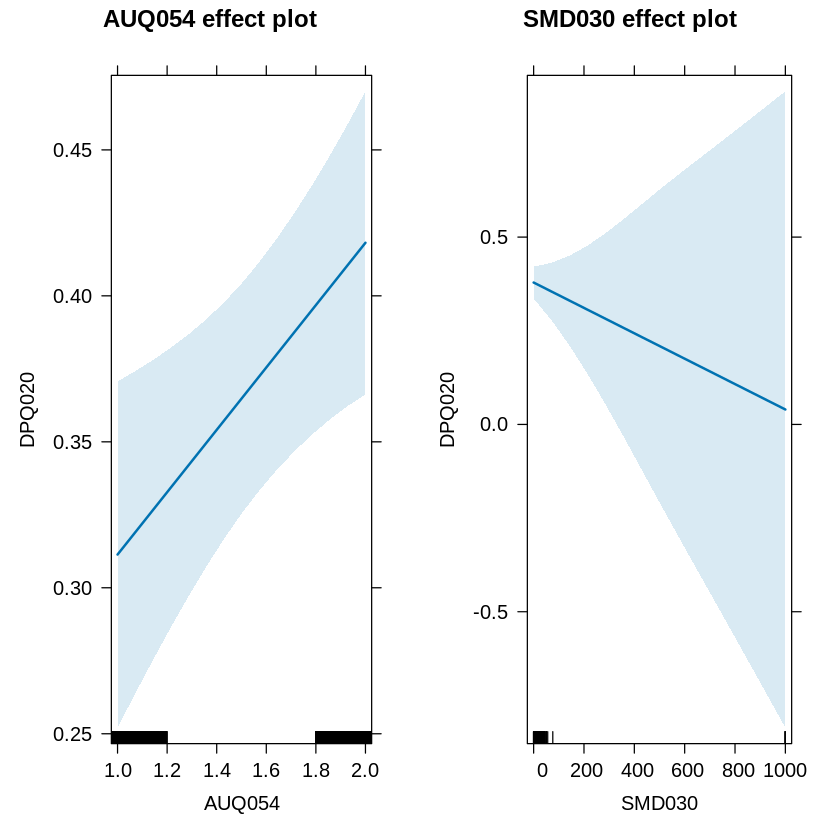

In [ ]:
plot(allEffects(model_multi))

# **4. Depression difference among Hearing Condition Group**

## 4.1 One-Way ANOVA

## 4.2 Post-hoc Analyses

## 4.3 t-Tests

## 4.4 Visualization of Depression Scores

# **5. Additional Multivariate Exploration**

## Correlation matrix

Select variables

In [ ]:
df_final <- df_final %>%
  mutate(
    hearing_numeric = as.numeric(hearing_level)
  )

In [ ]:
corr_vars <- df_final %>%
  select(
    phq9_total,        # Depression severity
    hearing_numeric,   # Hearing severity (numeric)
    RIDAGEYR,          # Age
    DMDEDUC2,          # Education
    INDHHIN2,          # Household income
    SMQ040             # Smoking status
  ) %>%
  drop_na()

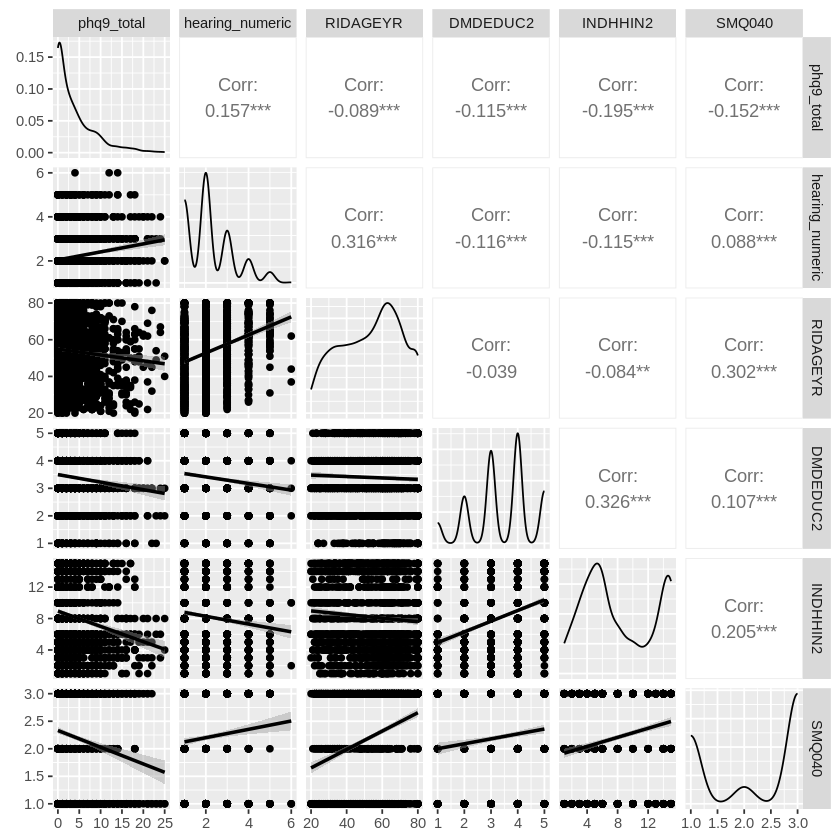

In [ ]:
ggpairs(
  corr_vars,
  lower = list(continuous = "smooth"),
  diag = list(continuous = "densityDiag"),
  upper = list(continuous = "cor")
)

## PCA

In [ ]:
pca_data <- corr_vars

In [ ]:
summary(pca_data)

   phq9_total     hearing_numeric    RIDAGEYR        DMDEDUC2    
 Min.   : 0.000   Min.   :1.000   Min.   :20.00   Min.   :1.000  
 1st Qu.: 0.000   1st Qu.:1.000   1st Qu.:40.00   1st Qu.:3.000  
 Median : 2.000   Median :2.000   Median :56.00   Median :4.000  
 Mean   : 3.855   Mean   :2.184   Mean   :53.66   Mean   :3.393  
 3rd Qu.: 6.000   3rd Qu.:3.000   3rd Qu.:67.00   3rd Qu.:4.000  
 Max.   :25.000   Max.   :6.000   Max.   :80.00   Max.   :5.000  
    INDHHIN2          SMQ040     
 Min.   : 1.000   Min.   :1.000  
 1st Qu.: 4.000   1st Qu.:1.000  
 Median : 6.000   Median :3.000  
 Mean   : 8.193   Mean   :2.215  
 3rd Qu.:14.000   3rd Qu.:3.000  
 Max.   :15.000   Max.   :3.000  

**Standarization**: applied to prevent variables with larger scales from dominating the principal components.

In [ ]:
pca_scaled <- scale(pca_data)

In [ ]:
pca_model <- prcomp(
  pca_scaled,
  center = TRUE,
  scale. = TRUE
)

In [ ]:
summary(pca_model)

Importance of components:
                          PC1    PC2    PC3    PC4    PC5     PC6
Standard deviation     1.2691 1.2210 0.9718 0.8565 0.8283 0.73111
Proportion of Variance 0.2684 0.2485 0.1574 0.1223 0.1143 0.08909
Cumulative Proportion  0.2684 0.5169 0.6743 0.7966 0.9109 1.00000

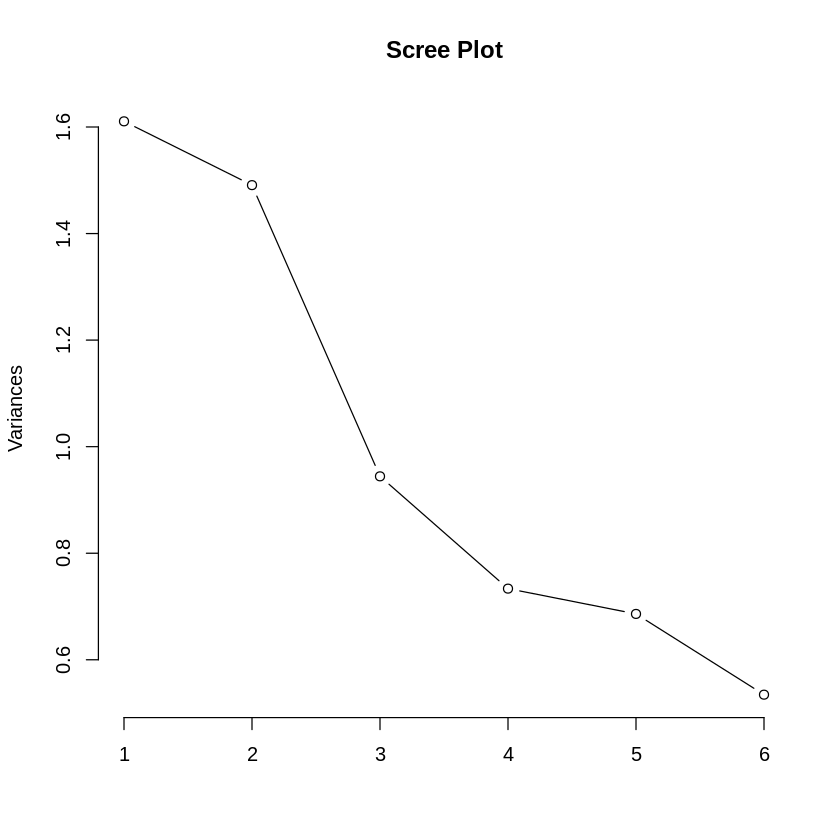

In [ ]:
plot(
  pca_model,
  type = "l",
  main = "Scree Plot"
)

Eigenvalues

In [ ]:
pca_model$sdev^2

[1] 1.6106298 1.4908924 0.9443150 0.7335548 0.6860806 0.5345273

In [ ]:
loadings <- pca_model$rotation
round(loadings, 3)

,PC1,PC2,PC3,PC4,PC5,PC6
phq9_total,0.439,0.093,0.710,0.413,-0.245,-0.252
hearing_numeric,0.290,-0.517,0.384,-0.322,0.506,0.377
RIDAGEYR,0.033,-0.675,-0.125,-0.222,-0.285,-0.630
DMDEDUC2,-0.513,0.058,0.494,-0.478,-0.472,0.196
INDHHIN2,-0.587,0.023,0.296,0.184,0.581,-0.442
SMQ040,-0.338,-0.515,-0.024,0.644,-0.205,0.405


In [ ]:
scores <- as.data.frame(pca_model$x)
head(scores)

,PC1,PC2,PC3,PC4,PC5,PC6
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0.6274783,-1.0158472,-1.7147367004,0.48633495,-0.3256775,0.2727594
2,0.9983397,0.7541009,-0.1722274651,-0.21447639,-0.8386580,-1.5243460
3,0.9129303,-0.4325576,0.0285158897,-1.13701322,0.4907859,-0.9510548
4,-1.8300923,-1.0368585,1.0819614639,-0.38216728,0.3531035,0.0852876
5,0.8373626,-1.0983530,-2.0382965736,0.98275654,0.3325256,-0.1315795
6,-2.5370855,-0.4816074,-0.0001327462,-0.08204704,-0.6309175,-0.8410206


# **BORRAR????????????**

## MODEL 1: DEMOGRAPHIC

### General Hearing Conditions Across Age Groups

In [ ]:
merged_data <- demo_data %>%
  select(SEQN, RIDAGEYR, RIAGENDR) %>%
  inner_join(hearing_data %>% select(SEQN, AUQ054), by = "SEQN")

In [ ]:
merged_data <- merged_data %>%
  filter(!AUQ054 %in% c(77, 99)) %>%
  mutate(
    AUQ054 = factor(AUQ054,
                    levels = 1:6,
                    labels = c("Excellent", "Good", "A little trouble",
                               "Moderate hearing trouble", "A lot of trouble",
                               "Deaf")),
    age_group = case_when(
      RIDAGEYR < 40 ~ "20-39",
      RIDAGEYR >= 40 & RIDAGEYR < 60 ~ "40-59",
      RIDAGEYR >= 60 ~ "60+"
    )
  )


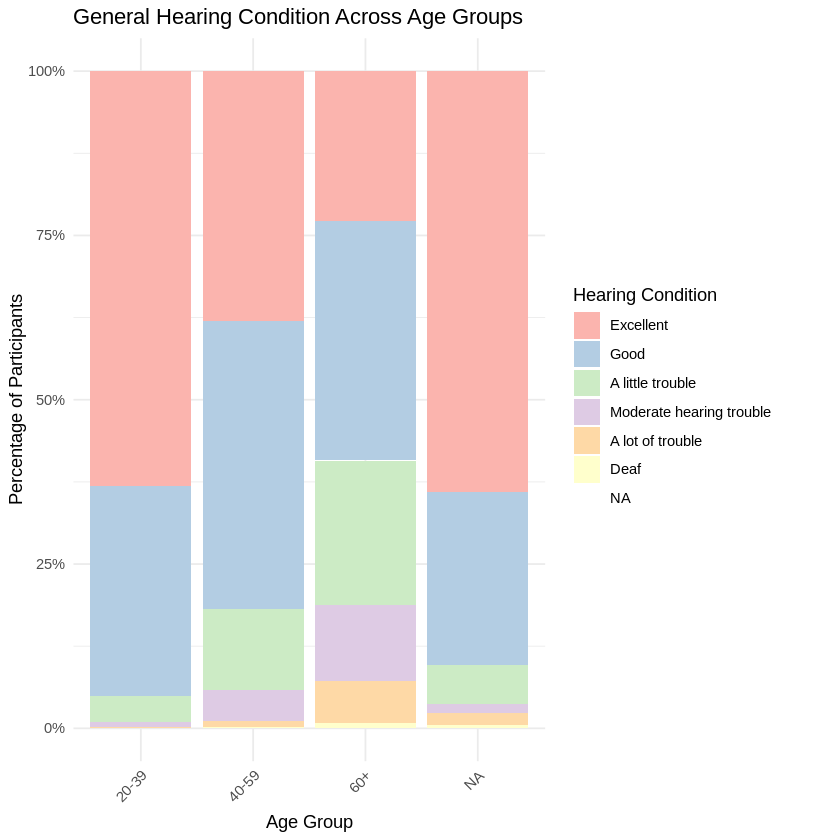

In [ ]:
ggplot(merged_data, aes(x = age_group, fill = AUQ054)) +
  geom_bar(position = "fill") +
  scale_y_continuous(labels = percent_format()) +
  labs(
    title = "General Hearing Condition Across Age Groups",
    x = "Age Group",
    y = "Percentage of Participants",
    fill = "Hearing Condition"
  ) +
  theme_minimal() +
     scale_fill_brewer(palette = "Pastel1") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))


### Age vs. Hearing Loss Probability

Shows whether hearing loss increases with age, and if depression is more common among those with hearing problems in older groups

### Test Statistic

In [ ]:
names(df_clean)

[1] "SEQN"      "SDDSRVYR"  "RIDSTATR"  "RIAGENDR"  "RIDAGEYR"  "RIDAGEMN" 
  [7] "RIDRETH1"  "RIDRETH3"  "RIDEXMON"  "RIDEXAGM"  "DMQMILIZ"  "DMQADFC"  
 [13] "DMDBORN4"  "DMDCITZN"  "DMDYRSUS"  "DMDEDUC3"  "DMDEDUC2"  "DMDMARTL" 
 [19] "RIDEXPRG"  "SIALANG"   "SIAPROXY"  "SIAINTRP"  "FIALANG"   "FIAPROXY" 
 [25] "FIAINTRP"  "MIALANG"   "MIAPROXY"  "MIAINTRP"  "AIALANGA"  "DMDHHSIZ" 
 [31] "DMDFMSIZ"  "DMDHHSZA"  "DMDHHSZB"  "DMDHHSZE"  "DMDHRGND"  "DMDHRAGZ" 
 [37] "DMDHREDZ"  "DMDHRMAZ"  "DMDHSEDZ"  "WTINT2YR"  "WTMEC2YR"  "SDMVPSU"  
 [43] "SDMVSTRA"  "INDHHIN2"  "INDFMIN2"  "INDFMPIR"  "DPQ010"    "DPQ020"   
 [49] "DPQ030"    "DPQ040"    "DPQ050"    "DPQ060"    "DPQ070"    "DPQ080"   
 [55] "DPQ090"    "DPQ100"    "AUQ054"    "AUQ060"    "AUQ070"    "AUQ080"   
 [61] "AUQ090"    "AUQ400"    "AUQ410A"   "AUQ410B"   "AUQ410C"   "AUQ410D"  
 [67] "AUQ410E"   "AUQ410F"   "AUQ410G"   "AUQ410H"   "AUQ410I"   "AUQ410J"  
 [73] "AUQ156"    "AUQ420"    "AUQ430"    "AUQ139"    "AUQ144"    "AUQ147"   
 [79] "AUQ149A"   "AUQ149B"   "AUQ149C"   "AUQ153"    "AUQ630"    "AUQ440"   
 [85] "AUQ450A"   "AUQ450B"   "AUQ450C"   "AUQ450D"   "AUQ450E"   "AUQ450F"  
 [91] "AUQ460"    "AUQ470"    "AUQ101"    "AUQ110"    "AUQ480"    "AUQ490"   
 [97] "AUQ191"    "AUQ250"    "AUQ255"    "AUQ260"    "AUQ270"    "AUQ280"   
[103] "AUQ500"    "AUQ300"    "AUQ310"    "AUQ320"    "AUQ330"    "AUQ340"   
[109] "AUQ350"    "AUQ360"    "AUQ370"    "AUQ510"    "AUQ380"    "SMQ020"   
[115] "SMD030"    "SMQ040"    "SMQ050Q"   "SMQ050U"   "SMD057"    "SMQ078"   
[121] "SMD641"    "SMD650"    "SMD093"    "SMDUPCA"   "SMD100BR"  "SMD100FL" 
[127] "SMD100MN"  "SMD100LN"  "SMD100TR"  "SMD100NI"  "SMD100CO"  "SMQ621"   
[133] "SMD630"    "SMQ661"    "SMQ665A"   "SMQ665B"   "SMQ665C"   "SMQ665D"  
[139] "SMQ670"    "SMQ848"    "SMQ852Q"   "SMQ852U"   "SMQ890"    "SMQ895"   
[145] "SMQ900"    "SMQ905"    "SMQ910"    "SMQ915"    "SMAQUEX2"  "age_group"

In [ ]:
# Sum PHQ-9 items to make a total score
df_clean <- df_clean %>%
  mutate(depression_score = rowSums(select(., DPQ010:DPQ090), na.rm = TRUE))


By Sex

In [ ]:
# Depression by sex
t.test(depression_score ~ RIAGENDR, data = df_clean)

# Hearing by sex
t.test(AUQ054 ~ RIAGENDR, data = df_clean)



	Welch Two Sample t-test

data:  depression_score by RIAGENDR
t = -7.1932, df = 5784.5, p-value = 7.131e-13
alternative hypothesis: true difference in means between group 1 and group 2 is not equal to 0
95 percent confidence interval:
 -0.9791211 -0.5597351
sample estimates:
mean in group 1 mean in group 2 
       2.421670        3.191098 



	Welch Two Sample t-test

data:  AUQ054 by RIAGENDR
t = 5.3974, df = 5703.8, p-value = 7.033e-08
alternative hypothesis: true difference in means between group 1 and group 2 is not equal to 0
95 percent confidence interval:
 0.09285146 0.19877004
sample estimates:
mean in group 1 mean in group 2 
       2.060412        1.914601 


## MODEL 2: SOCIOECONOMIC CONTROLS

### Hearing Aid Use by Household Income

In [ ]:
merged_data <- merge(hearing_data, demo_data, by = "SEQN")


In [ ]:
merged_data <- merged_data %>%
  mutate(
    AUQ054 = factor(AUQ054,
                    levels = c(1, 2, 3),
                    labels = c("Never", "Sometimes", "Always")),

    Income = factor(INDHHIN2,
                    levels = c(1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 77, 99),
                    labels = c(
                      "$0 to $4,999",
                      "$5,000 to $9,999",
                      "$10,000 to $14,999",
                      "$15,000 to $19,999",
                      "$20,000 to $24,999",
                      "$25,000 to $34,999",
                      "$35,000 to $44,999",
                      "$45,000 to $54,999",
                      "$55,000 to $64,999",
                      "$65,000 to $74,999",
                      "$20,000 and Over",
                      "Under $20,000",
                      "$75,000 to $99,999",
                      "$100,000 and Over",
                      "Refused",
                      "Don't know"
                    ))
  )


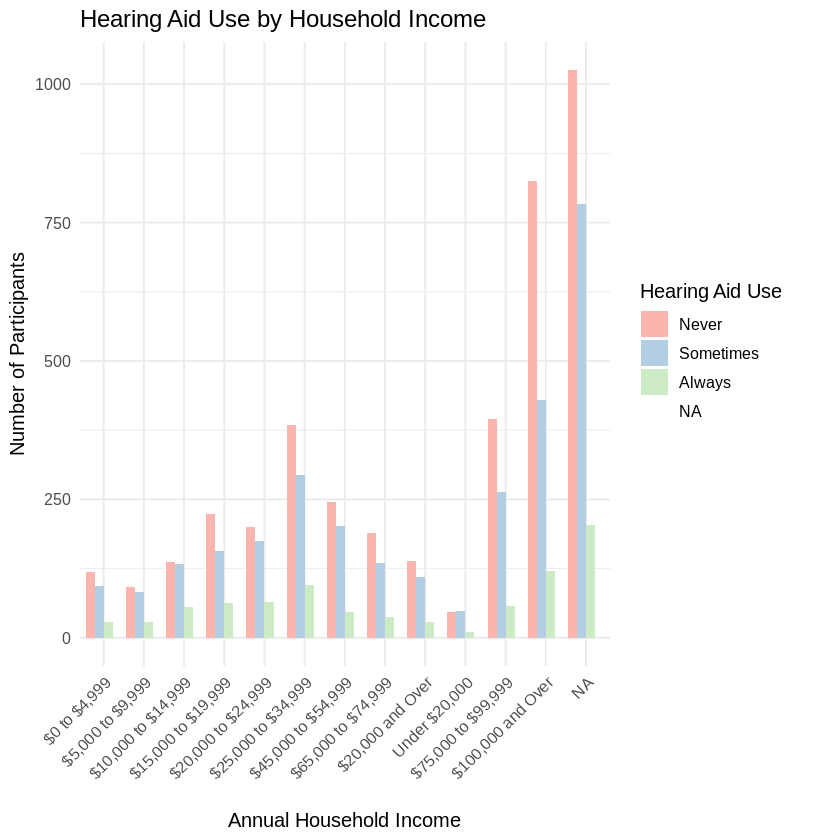

In [ ]:
ggplot(merged_data, aes(x = Income, fill = AUQ054)) +
  geom_bar(position = "dodge") +
  labs(
    title = "Hearing Aid Use by Household Income",
    x = "Annual Household Income",
    y = "Number of Participants",
    fill = "Hearing Aid Use"
  ) +
    scale_fill_brewer(palette = "Pastel1") +
  theme_minimal(base_size = 12) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))
